<a href="https://colab.research.google.com/github/sumitpaul398/ML-projects/blob/main/Class_SVC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# import iris database

In [ ]:
from sklearn.datasets import load_iris
from sklearn.svm import SVC

iris = load_iris()

In [ ]:
dir(iris)

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [ ]:
iris["DESCR"]

'.. _iris_dataset:\n\nIris plants dataset\n--------------------\n\n**Data Set Characteristics:**\n\n    :Number of Instances: 150 (50 in each of three classes)\n    :Number of Attributes: 4 numeric, predictive attributes and the class\n    :Attribute Information:\n        - sepal length in cm\n        - sepal width in cm\n        - petal length in cm\n        - petal width in cm\n        - class:\n                - Iris-Setosa\n                - Iris-Versicolour\n                - Iris-Virginica\n                \n    :Summary Statistics:\n\n    ============== ==== ==== ======= ===== ====================\n                    Min  Max   Mean    SD   Class Correlation\n    ============== ==== ==== ======= ===== ====================\n    sepal length:   4.3  7.9   5.84   0.83    0.7826\n    sepal width:    2.0  4.4   3.05   0.43   -0.4194\n    petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)\n    petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)\n    ============== ==== =

In [ ]:
iris["feature_names"]

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [ ]:
iris["target_names"]

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [ ]:
iris["data"]

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

# convert to pandas

In [ ]:
df = pd.DataFrame(iris.data, columns= iris.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# visualize the data

In [ ]:
X = iris["data"][:,(2,3)] # petal length and width
y = iris["target"]

In [ ]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [ ]:
setosa_or_versicolor = (y==0) | (y==1)

In [ ]:
setosa_or_versicolor

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [ ]:
X.shape

(150, 2)

In [ ]:
X = X[setosa_or_versicolor]
y=y[setosa_or_versicolor]


In [ ]:
X.shape

(100, 2)

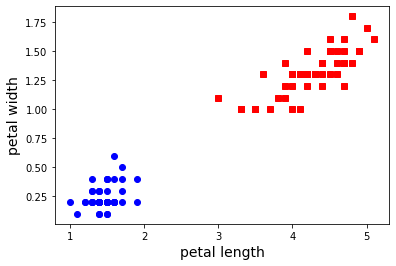

In [ ]:
plt.plot(X[:,0][y==1],X[:,1][y==1], 'rs', label = "iris versicolor")
plt.plot(X[:,0][y==0],X[:,1][y==0], 'bo', label = "iris sertosa")
plt.xlabel("petal length", fontsize =14)
plt.ylabel("petal width", fontsize = 14)
plt.show()


# train the model

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
X = iris["data"][:,(2,3)] # petal width and length
y = (iris["target"]==2).astype(np.float64) # iris virginica

In [ ]:
y

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [ ]:
svm_clf1 = SVC(C=1, kernel = "linear", random_state= 42)
scaled_svm_clf1 = Pipeline([
                  #  ("Scaler", StandardScaler()),
                    ("svr",svm_clf1)
])

scaled_svm_clf1.fit(X,y)

Pipeline(steps=[('svr', SVC(C=1, kernel='linear', random_state=42))])

# predict a value

In [ ]:
svm_clf1.predict([[5.5,1.7]])

array([1.])

# visualize the results

In [ ]:
def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]

    # At the decision boundary, w0*x0 + w1*x1 + b = 0
    # => x1 = -w0/w1 * x0 - b/w1
    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0]/w[1] * x0 - b/w[1]

    margin = 1/w[1]  # margin
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin

    svs = svm_clf.support_vectors_
    plt.scatter(svs[:, 0], svs[:, 1], s=180, facecolors='#FFAAAA')
    plt.plot(x0, decision_boundary, "k-", linewidth=3)
    plt.plot(x0, gutter_up, "k--", linewidth=5)
    plt.plot(x0, gutter_down, "k--", linewidth=5)

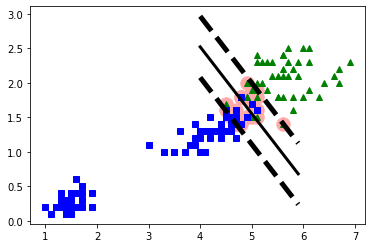

In [ ]:
plt.plot(X[:,0][y==1], X[:,1][y==1], 'g^', label = "iris virginica")
plt.plot(X[:,0][y==0], X[:,1][y==0], 'bs', label = "non virginica")
plot_svc_decision_boundary(svm_clf1, 4, 5.9)

In [ ]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
X,y = make_moons(n_samples=500, noise=0.15, random_state=42)
x=X

# show moon data

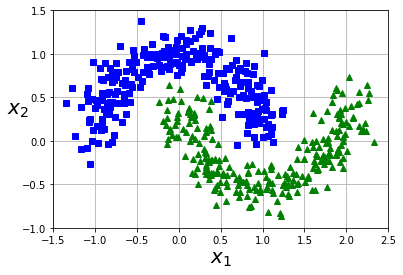

In [ ]:
def plot_dataset(X, y, axes):
    plt.plot(x[:, 0][y==0], x[:, 1][y==0], "bs")
    plt.plot(x[:, 0][y==1], x[:, 1][y==1], "g^")
    plt.axis(axes)
    plt.grid(True, which='both')
    plt.xlabel(r"$x_1$", fontsize=20)
    plt.ylabel(r"$x_2$", fontsize=20, rotation=0)

plot_dataset(x, y, [-1.5, 2.5, -1, 1.5])
plt.show()

Use Linear model to predict

In [ ]:
# use linear model to predict

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

svm_clf = SVC(kernel = 'linear', random_state=0)
svm_clf.fit(X_train, y_train)

SVC(kernel='linear', random_state=0)

In [ ]:
y_pred = svm_clf.predict(X_test)

# confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[40  3]
 [11 46]]


In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[40  3]
 [11 46]]


In [ ]:
rows_sums = cm.sum(axis = 1, keepdims = True)
norm_cm = cm/rows_sums

plt.

SyntaxError: ignored

In [ ]:
from sklearn.metrics import precision_score, recall_score
precision_score(y_test, y_pred)

In [ ]:
recall_score(y_test, y_pred)

# use polynomial features to imporve perfromance

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

polynomial_svm_clf = Pipeline([
          ('poly_features', PolynomialFeatures(degree =3)),
          ('scaler', StandardScaler()),
          ('svm_clf', LinearSVC(C=10, loss = 'hinge', random_state=42))
])

polynomial_svm_clf.fit(X_train,y_train)

In [ ]:
y_pred = polynomial_svm_clf.predict(X_test)

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

# visulaize the results

In [ ]:
plot_dataset(X_test, y_pred, [-1.5, 2.5, -1, 1.5])
plt.plot(X_test[:,0][y_test==0], X_test[:,1][y_test==0], 'rs')
plt.plot(X_test[:,0][y_test==1], X_test[:,1][y_test==1], 'yt')
plot_svc_decision_boundary(svm_clf1, 4, 5.9)

In [ ]:
    plt.plot(X[:, 0][y==0], X[:, 1][y==0], "bs")
    plt.plot(X[:, 0][y==1], X[:, 1][y==1], "g^")
    plt.axis(axes)
    plt.grid(True, which='both')
    plt.xlabel(r"$x_1$", fontsize=20)
    plt.ylabel(r"$x_2$", fontsize=20, rotation=0)

plot_dataset(X, y, [-1.5, 2.5, -1, 1.5])
plt.show()
def plotSVC(title):
  # create a mesh to plot in
  x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
  y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1
  hx = (x_max - x_min)/100
  hy = (y_max - y_min)/100
  xx, yy = np.meshgrid(np.arange(x_min, x_max, hx),
  np.arange(y_min, y_max, hy))
  plt.subplot(1, 1, 1)
  y_pred = svc.predict(X_test)
  precision = precision_score(y_test,y_pred)
  recall = recall_score(y_test,y_pred)

  Z = svc.predict(np.c_[xx.ravel(), yy.ravel()])
  Z = Z.reshape(xx.shape)
  #plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.jet)
  plt.plot(X[:, 0][y==0], X[:, 1][y==0], 'r^')
  plt.plot(X[:, 0][y==1], X[:, 1][y==1], 'bo')
  plt.plot(X[:, 0][y==2], X[:, 1][y==2], 'k+')
  plt.contourf(xx, yy, Z, cmap=plt.cm.jet, alpha=0.8)
  plt.xlabel('Sepal length')
  plt.ylabel('Petal length')
  plt.xlim(xx.min(), xx.max())
  title = f"{title}, precision is {precisio}. recall is {recall}"
  plt.title(title)
  plt.show()

# compare linear, RBF and poly

In [ ]:
from sklearn import svm, datasets

kernels = ['linear', 'rbf','poly']

for kernel in kernels:
  svc = svm.SVC(kernel = kernel).fit(X,y)
  plotSVC('kernel=' + str(kernel))



# gamma

In [ ]:
gammas = [0.1, 1 10, 100]

for gamma in gammas:
  SVC = svm.SVC(kernel = "rbf", gamma = gamma).fit(X_train, y_train)
  plotSVC("gamma=" + str(gamma))



# effect of hyperparameter C

In [ ]:
cs = [0.1, 1,10, 100,1000]

for c in cs:
  svc = svm.SVC(kernel= "rbf", C=c).fit(X_train, y_train)
  plotSVC("C=" + str(c))

# degree

In [ ]:
# code same as gamma and C